# FIREWATCH AI — Dataset Reconnaissance

**Stage:** 01 · Data inventory and quality baseline  
**Purpose:** Inspect the FIRMS CSV files delivered in `2025/` and `2026/` before designing ingestion, harmonization, analytics, or UI.

This notebook reads original files without modifying them. It discovers source files, records product and satellite metadata, checks schemas, coverage, missing values, exact duplicate rows, coordinate ranges, and archive/NRT coverage. Outputs are displayed in the notebook; the companion report captures the initial findings.

**Run:** execute cells from top to bottom in the repository root (or let the root-discovery cell locate it).

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project root from the current notebook location.
def find_project_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / "2025").is_dir() and (candidate / "2026").is_dir():
            return candidate
    raise FileNotFoundError("Could not find project root containing 2025/ and 2026/.")

PROJECT_ROOT = find_project_root()
DATA_DIRS = [PROJECT_ROOT / "2025", PROJECT_ROOT / "2026"]
print(f"Project root: {PROJECT_ROOT}")
print("Data directories:", ", ".join(str(p) for p in DATA_DIRS))

Project root: C:\Users\ngong\Documents\NASA CHALLENGE
Data directories: C:\Users\ngong\Documents\NASA CHALLENGE\2025, C:\Users\ngong\Documents\NASA CHALLENGE\2026


## Product-code interpretation

FIRMS delivery codes in the filenames identify four input streams: `M-C61` (MODIS C6.1, containing Terra and Aqua records), `SV-C2` (Suomi-NPP VIIRS), `J1V-C2` (NOAA-20 VIIRS), and `J2V-C2` (NOAA-21 VIIRS). The CSV values and readme files are still inspected below; filename interpretation is not used to overwrite the row-level `satellite`, `instrument`, or `version` values.

In [2]:
csv_files = sorted(p for folder in DATA_DIRS for p in folder.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError("No CSV files found under the 2025/ and 2026/ data directories.")

def infer_product(path):
    name = path.name
    for code in ("M-C61", "SV-C2", "J1V-C2", "J2V-C2"):
        if code in name:
            return code
    return "unknown"

def infer_stream(path):
    if "fire_archive_" in path.name: return "archive"
    if "fire_nrt_" in path.name: return "near_real_time"
    return "unknown"

file_inventory = []
for path in csv_files:
    header = pd.read_csv(path, nrows=0).columns.tolist()
    file_inventory.append({
        "year_folder": path.parent.parent.name,
        "product_code": infer_product(path),
        "stream": infer_stream(path),
        "file": str(path.relative_to(PROJECT_ROOT)),
        "size_mb": round(path.stat().st_size / 1_000_000, 3),
        "columns": len(header),
        "schema": ", ".join(header),
    })
inventory = pd.DataFrame(file_inventory)
display(inventory[["year_folder", "product_code", "stream", "file", "size_mb", "columns"]])
print(f"CSV files discovered: {len(inventory)}")

,year_folder,product_code,stream,file,size_mb,columns
0,2025,J1V-C2,archive,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,17.820,15
1,2025,J2V-C2,archive,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,17.315,15
2,2025,M-C61,archive,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,3.265,15
3,2025,SV-C2,archive,2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_8...,18.033,15
4,2026,J1V-C2,archive,2026\DL_FIRE_J1V-C2_846761\fire_archive_J1V-C2...,10.525,15
5,2026,J1V-C2,near_real_time,2026\DL_FIRE_J1V-C2_846761\fire_nrt_J1V-C2_846...,0.303,14
6,2026,J2V-C2,archive,2026\DL_FIRE_J2V-C2_846762\fire_archive_J2V-C2...,10.030,15
7,2026,J2V-C2,near_real_time,2026\DL_FIRE_J2V-C2_846762\fire_nrt_J2V-C2_846...,0.277,14
8,2026,M-C61,archive,2026\DL_FIRE_M-C61_846760\fire_archive_M-C61_8...,1.458,15
9,2026,M-C61,near_real_time,2026\DL_FIRE_M-C61_846760\fire_nrt_M-C61_84676...,0.026,14


CSV files discovered: 12


## Record, schema, quality, and coverage audit

Exact duplicate detection uses a SHA-256 digest of each raw CSV record line. This keeps the check bounded in memory and deliberately distinguishes byte-identical duplicate rows from near-duplicates, which are a separate scientific association problem. Empty fields and invalid numeric/date values are counted separately. Coordinates and source metadata remain in their original columns.

In [3]:
quality_rows = []
all_schemas = {}
for path in csv_files:
    df = pd.read_csv(path, dtype={"acq_time": "string"}, low_memory=False)
    cols = tuple(df.columns)
    all_schemas.setdefault(cols, []).append(str(path.relative_to(PROJECT_ROOT)))
    blank_cells = int(df.isna().sum().sum()) + int(df.astype("string").apply(lambda c: c.str.strip().eq("").sum()).sum())
    exact_duplicate_rows = int(df.duplicated(keep="first").sum())
    dates = pd.to_datetime(df.get("acq_date"), errors="coerce")
    lat = pd.to_numeric(df.get("latitude"), errors="coerce")
    lon = pd.to_numeric(df.get("longitude"), errors="coerce")
    quality_rows.append({
        "year_folder": path.parent.parent.name, "product_code": infer_product(path),
        "stream": infer_stream(path), "file": str(path.relative_to(PROJECT_ROOT)),
        "records": len(df), "columns": len(df.columns), "missing_or_blank_cells": blank_cells,
        "exact_duplicate_rows": exact_duplicate_rows,
        "invalid_dates": int(dates.isna().sum()),
        "invalid_coordinates": int((lat.isna() | lon.isna() | ~lat.between(-90,90) | ~lon.between(-180,180)).sum()),
        "first_observation": dates.min(), "last_observation": dates.max(),
        "latitude_min": lat.min(), "latitude_max": lat.max(),
        "longitude_min": lon.min(), "longitude_max": lon.max(),
        "satellites": ", ".join(sorted(df["satellite"].dropna().astype(str).unique())) if "satellite" in df else "",
        "instruments": ", ".join(sorted(df["instrument"].dropna().astype(str).unique())) if "instrument" in df else "",
        "versions": ", ".join(sorted(df["version"].dropna().astype(str).unique())) if "version" in df else "",
    })
    del df
quality = pd.DataFrame(quality_rows)
display(quality.drop(columns=["file"]).sort_values(["year_folder", "product_code", "stream"]))
print("Distinct schemas:", len(all_schemas))
for schema, files in all_schemas.items():
    print(f"\n{len(schema)} columns: {', '.join(schema)}")
    for file in files: print("  -", file)

,year_folder,product_code,stream,records,columns,missing_or_blank_cells,exact_duplicate_rows,invalid_dates,invalid_coordinates,first_observation,last_observation,latitude_min,latitude_max,longitude_min,longitude_max,satellites,instruments,versions
0,2025,J1V-C2,archive,224606,15,0,0,0,0,2025-01-01,2025-12-31,1.85855,13.07508,8.59549,16.08756,N20,VIIRS,2
1,2025,J2V-C2,archive,218188,15,0,0,0,0,2025-01-01,2025-12-31,1.91726,13.07825,8.61726,16.09902,N21,VIIRS,2
2,2025,M-C61,archive,42120,15,0,0,0,0,2025-01-01,2025-12-31,1.89080,13.01480,8.61900,16.07700,"Aqua, Terra",MODIS,61.03
3,2025,SV-C2,archive,227320,15,0,0,0,0,2025-01-01,2025-12-31,1.91950,13.08036,8.59132,16.07950,SNPP,SNPP,2
4,2026,J1V-C2,archive,132632,15,0,0,0,0,2026-01-01,2026-07-31,1.93987,13.07966,8.51280,16.08368,N20,VIIRS,2
5,2026,J1V-C2,near_real_time,3640,14,0,0,0,0,2026-08-01,2026-11-02,2.08468,13.06735,9.84897,16.06632,N20,VIIRS,2.0NRT
6,2026,J2V-C2,archive,126367,15,0,0,0,0,2026-01-01,2026-07-31,1.89271,13.07981,8.60890,16.06669,N21,VIIRS,2
7,2026,J2V-C2,near_real_time,3332,14,0,0,0,0,2026-08-01,2026-11-02,2.15530,13.06859,9.24010,16.06612,N21,VIIRS,2.0NRT
8,2026,M-C61,archive,18845,15,0,0,0,0,2026-01-01,2026-08-29,1.96080,13.07910,8.60530,16.04730,"Aqua, Terra",MODIS,61.03
9,2026,M-C61,near_real_time,306,14,0,0,0,0,2026-09-09,2026-11-02,2.15864,12.72848,9.94490,15.55990,"Aqua, Terra",MODIS,6.1NRT


Distinct schemas: 2

15 columns: latitude, longitude, brightness, scan, track, acq_date, acq_time, satellite, instrument, confidence, version, bright_t31, frp, daynight, type
  - 2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2_846755.csv
  - 2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2_846756.csv
  - 2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_846754.csv
  - 2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_846757.csv
  - 2026\DL_FIRE_J1V-C2_846761\fire_archive_J1V-C2_846761.csv
  - 2026\DL_FIRE_J2V-C2_846762\fire_archive_J2V-C2_846762.csv
  - 2026\DL_FIRE_M-C61_846760\fire_archive_M-C61_846760.csv
  - 2026\DL_FIRE_SV-C2_846763\fire_archive_SV-C2_846763.csv

14 columns: latitude, longitude, brightness, scan, track, acq_date, acq_time, satellite, instrument, confidence, version, bright_t31, frp, daynight
  - 2026\DL_FIRE_J1V-C2_846761\fire_nrt_J1V-C2_846761.csv
  - 2026\DL_FIRE_J2V-C2_846762\fire_nrt_J2V-C2_846762.csv
  - 2026\DL_FIRE_M-C61_846760\fire_nrt_M-C61_846760.csv
  - 2026\DL_FIRE

## Satellite and confidence distributions

Confidence encodings are reported as delivered. Do not interpret VIIRS `n/l/h` and numeric MODIS confidence as interchangeable scores without product-specific documentation and an explicit transformation policy.

In [4]:
distribution_rows = []
for path in csv_files:
    usecols = [c for c in ["satellite", "instrument", "confidence", "version", "daynight", "type"]
               if c in pd.read_csv(path, nrows=0).columns]
    df = pd.read_csv(path, usecols=usecols, dtype="string", low_memory=False)
    for col in usecols:
        counts = df[col].fillna("<missing>").value_counts(dropna=False)
        for value, count in counts.items():
            distribution_rows.append({"file": str(path.relative_to(PROJECT_ROOT)), "field": col, "value": value, "records": int(count)})
    del df
distributions = pd.DataFrame(distribution_rows)
for field in ["satellite", "instrument", "version", "confidence", "daynight", "type"]:
    subset = distributions[distributions.field.eq(field)]
    if not subset.empty:
        print(f"\n### {field}")
        display(subset.groupby(["file", "value"], as_index=False).records.sum())


### satellite


,file,value,records
0,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,N20,224606
1,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,N21,218188
2,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,Aqua,35900
3,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,Terra,6220
4,2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_8...,SNPP,227320
5,2026\DL_FIRE_J1V-C2_846761\fire_archive_J1V-C2...,N20,132632
6,2026\DL_FIRE_J1V-C2_846761\fire_nrt_J1V-C2_846...,N20,3640
7,2026\DL_FIRE_J2V-C2_846762\fire_archive_J2V-C2...,N21,126367
8,2026\DL_FIRE_J2V-C2_846762\fire_nrt_J2V-C2_846...,N21,3332
9,2026\DL_FIRE_M-C61_846760\fire_archive_M-C61_8...,Aqua,15938



### instrument


,file,value,records
0,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,VIIRS,224606
1,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,VIIRS,218188
2,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,MODIS,42120
3,2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_8...,SNPP,227320
4,2026\DL_FIRE_J1V-C2_846761\fire_archive_J1V-C2...,VIIRS,132632
5,2026\DL_FIRE_J1V-C2_846761\fire_nrt_J1V-C2_846...,VIIRS,3640
6,2026\DL_FIRE_J2V-C2_846762\fire_archive_J2V-C2...,VIIRS,126367
7,2026\DL_FIRE_J2V-C2_846762\fire_nrt_J2V-C2_846...,VIIRS,3332
8,2026\DL_FIRE_M-C61_846760\fire_archive_M-C61_8...,MODIS,18845
9,2026\DL_FIRE_M-C61_846760\fire_nrt_M-C61_84676...,MODIS,306



### version


,file,value,records
0,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,2,224606
1,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,2,218188
2,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,61.03,42120
3,2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_8...,2,227320
4,2026\DL_FIRE_J1V-C2_846761\fire_archive_J1V-C2...,2,132632
5,2026\DL_FIRE_J1V-C2_846761\fire_nrt_J1V-C2_846...,2.0NRT,3640
6,2026\DL_FIRE_J2V-C2_846762\fire_archive_J2V-C2...,2,126367
7,2026\DL_FIRE_J2V-C2_846762\fire_nrt_J2V-C2_846...,2.0NRT,3332
8,2026\DL_FIRE_M-C61_846760\fire_archive_M-C61_8...,61.03,18845
9,2026\DL_FIRE_M-C61_846760\fire_nrt_M-C61_84676...,6.1NRT,306


... (2 outputs left out)


### daynight


,file,value,records
0,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,D,189804
1,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,N,34802
2,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,D,184370
3,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,N,33818
4,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,D,39145
5,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,N,2975
6,2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_8...,D,194132
7,2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_8...,N,33188
8,2026\DL_FIRE_J1V-C2_846761\fire_archive_J1V-C2...,D,112509
9,2026\DL_FIRE_J1V-C2_846761\fire_archive_J1V-C2...,N,20123



### type


,file,value,records
0,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,0,223809
1,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,2,669
2,2025\DL_FIRE_J1V-C2_846755\fire_archive_J1V-C2...,3,128
3,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,0,217459
4,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,2,645
5,2025\DL_FIRE_J2V-C2_846756\fire_archive_J2V-C2...,3,84
6,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,0,41989
7,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,1,26
8,2025\DL_FIRE_M-C61_846754\fire_archive_M-C61_8...,2,105
9,2025\DL_FIRE_SV-C2_846757\fire_archive_SV-C2_8...,0,226580


## Coverage visualization

The bars represent the first and last observation dates present in each file. They do not establish complete daily coverage between those dates; use row counts and explicit date-level coverage checks before interpreting a gap as absent fire activity.

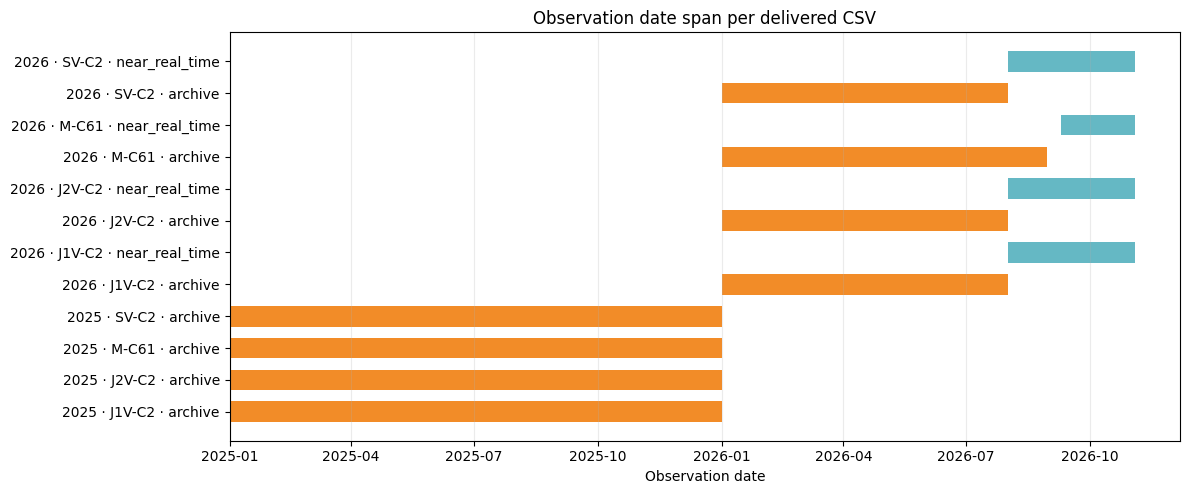

In [5]:
fig, ax = plt.subplots(figsize=(12, max(4, 0.42 * len(quality))))
plot_df = quality.sort_values(["year_folder", "product_code", "stream"]).reset_index(drop=True)
for y, row in plot_df.iterrows():
    start, end = row["first_observation"], row["last_observation"]
    if pd.notna(start) and pd.notna(end):
        ax.barh(y, (end-start).days + 1, left=start, height=0.65,
                color="#f28c28" if row["stream"] == "archive" else "#65b8c4")
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels([f"{r.year_folder} · {r.product_code} · {r.stream}" for r in plot_df.itertuples()])
ax.set_title("Observation date span per delivered CSV")
ax.set_xlabel("Observation date")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## Reconciliation and handoff

Summarize row counts by year, product, and stream. The pipeline should preserve source-file provenance and distinguish archive from NRT records. Before event harmonization, we will define an explicit policy for stream overlap and how daily/monthly calendars count raw observations versus inferred event clusters.

In [6]:
summary = (quality.groupby(["year_folder", "product_code", "stream"], as_index=False)
           .agg(records=("records", "sum"), first_observation=("first_observation", "min"),
                last_observation=("last_observation", "max"), files=("file", "count")))
display(summary)
print("All-source totals by year:")
display(quality.groupby("year_folder", as_index=False).records.sum())
print("Audit complete. Original CSVs were opened read-only; no source data was written.")

,year_folder,product_code,stream,records,first_observation,last_observation,files
0,2025,J1V-C2,archive,224606,2025-01-01,2025-12-31,1
1,2025,J2V-C2,archive,218188,2025-01-01,2025-12-31,1
2,2025,M-C61,archive,42120,2025-01-01,2025-12-31,1
3,2025,SV-C2,archive,227320,2025-01-01,2025-12-31,1
4,2026,J1V-C2,archive,132632,2026-01-01,2026-07-31,1
5,2026,J1V-C2,near_real_time,3640,2026-08-01,2026-11-02,1
6,2026,J2V-C2,archive,126367,2026-01-01,2026-07-31,1
7,2026,J2V-C2,near_real_time,3332,2026-08-01,2026-11-02,1
8,2026,M-C61,archive,18845,2026-01-01,2026-08-29,1
9,2026,M-C61,near_real_time,306,2026-09-09,2026-11-02,1


All-source totals by year:


,year_folder,records
0,2025,712234
1,2026,417793


Audit complete. Original CSVs were opened read-only; no source data was written.


## Research notes and unresolved decisions

- Confirm exact FIRMS product documentation and the definitions/units for every measurement before modeling.
- Verify the geographic extent and whether each delivered CSV is a regional subset or global extract.
- Check whether the ZIP contents exactly match the extracted CSVs and retain download metadata if available.
- Determine archive/NRT overlap, update cadence, and replacement semantics before merging streams.
- Select geospatial indexing and association thresholds only after data distributions and sampling behavior are understood.
- Define separate outputs for raw detection counts, spatial-temporal association candidates, and calendar-level activity summaries.
